REGISTROS lidos do cache /content/registros.csv
  24,354 linhas × 36 colunas
7 tipos; exemplos de features de célula:
 n_bos_A  n_bos_celula_A  share_celula_A  cel_prop_FURTO_DE_VEICULO_A  cel_prop_LESAO_CORPORAL_CULPOSA_POR_ACIDENTE_DE_TRANSITO_A  cel_prop_ROUBO_DE_VEICULO_A
       1               5             0.2                         20.0                                                        80.0                          0.0
       1               5             0.2                         20.0                                                        80.0                          0.0
       1               5             0.2                         20.0                                                        80.0                          0.0
corte de cauda: 20 features em [0.5% ; 99.5%] (cel_lat/cel_lon preservadas)
X: 24,354 registros × 24 features  (2 categóricas + 22 numéricas)
y: 8 alvos -> n_bos_B (contagem) + 7 proporções
y de treino: total em log1p, mix em 'fracao'  |  TETO_TO

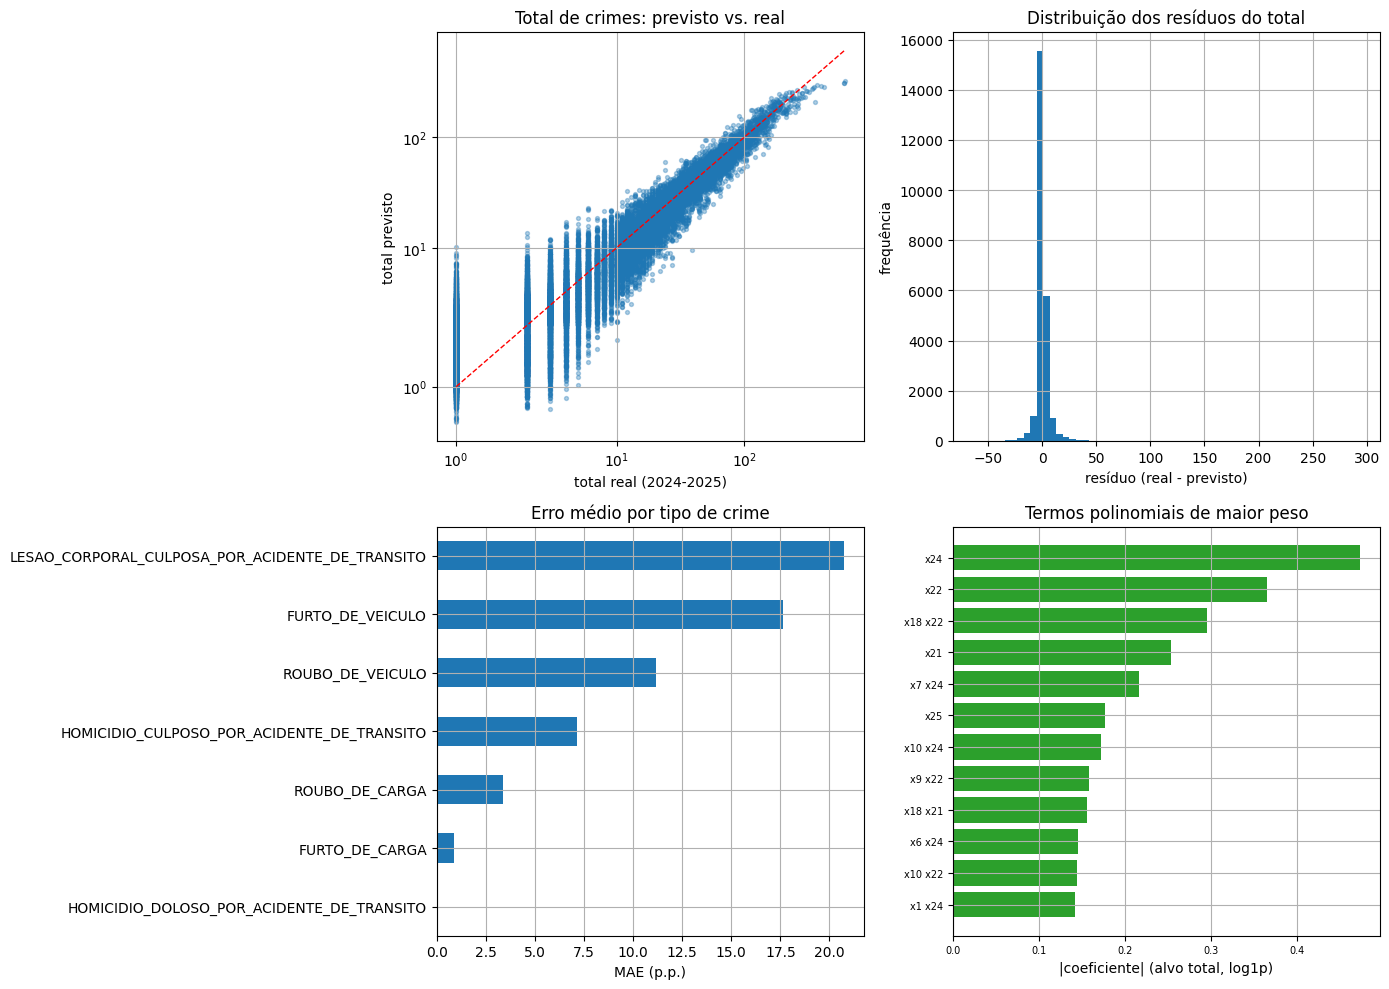

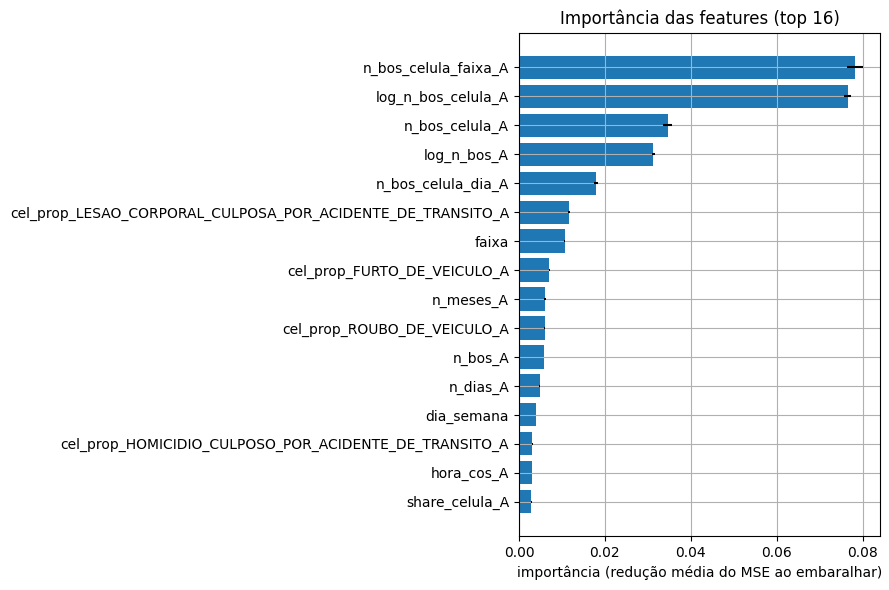

modelo       -> poly_melhor.joblib
registros    -> registros.csv
RESUMO DA PREVISÃO — janela de teste 2024-2025 (24,354 registros)
  total de crimes : o modelo polinomial erra 23,4% a MENOS que a persistência
                     (MAE 3,03 vs 3,96 crimes por registro)
  mix de tipos    : o modelo polinomial erra 12,6% a MENOS
                     (MAE 8,71 vs 9,97 pontos percentuais)
  indicadores     : R² = 0,934 | WAPE = 22,7% | acerto ±tolerância = 66,1% | sesgo = -0,58 crimes

Skill > 0 = melhor do que repetir 2022-23 | veredito = modelo vs persistência
|sesgo| < 0,5 é tratado como 'quase sem viés'
Atenção: as métricas de 'Acerto ±tolerância' podem discordar do MAE — a
persistência acerta mais pontos isolados mesmo tendo erro médio maior.

                           Polinomial Persistência Média global skill vs persist.        veredito
métrica                                                                                          
MAE (crimes)                     3,03         3,96

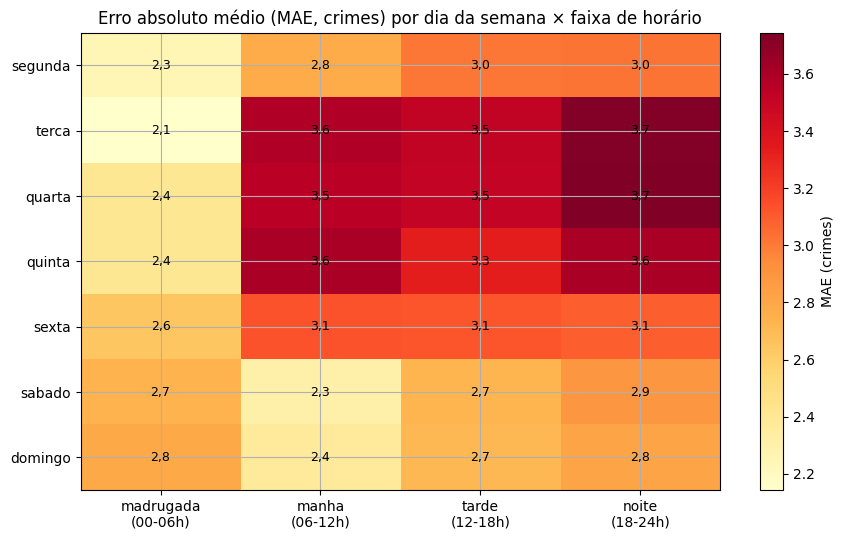

quanto mais escuro, pior; compare com o MAE global de 3,03 crimes


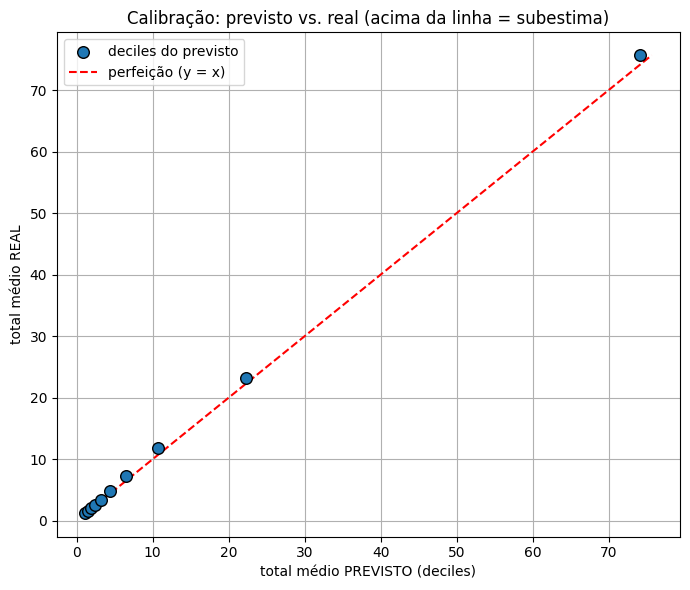

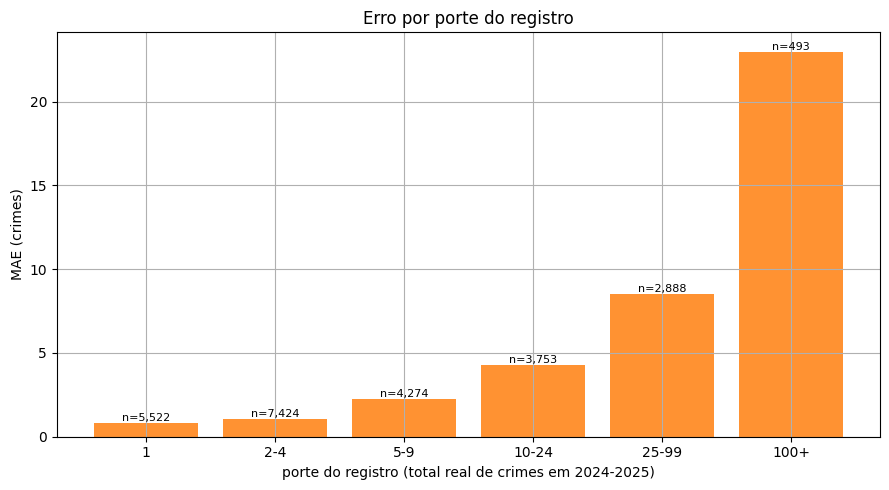

=== ERRO POR PORTE DO REGISTRO ===
           n MAE (crimes) WAPE (%) Acerto ±tol (%)
bin                                               
1      5.522         0,81    81,37           92,56
2-4    7.424         1,05    37,94           88,15
5-9    4.274         2,25    34,05           50,80
10-24  3.753         4,28    28,06           28,19
25-99  2.888         8,53    17,56           34,94
100+     493        22,98    15,24           41,18


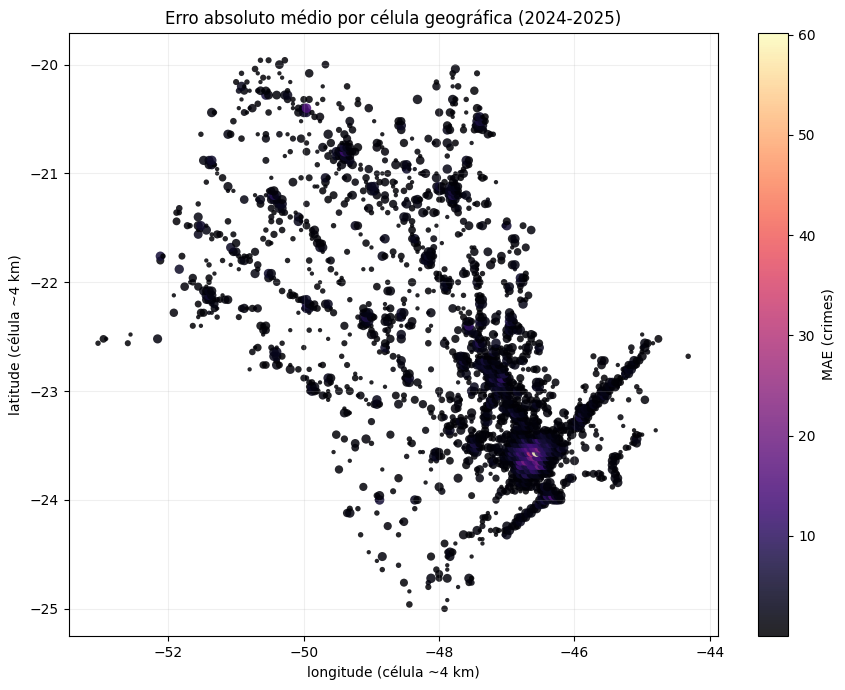

2,046 células com registros em ambas as janelas (bolha maior = mais registros na célula)
relatório tabular gravado em relatorio_metricas_poly.csv (21 linhas: resumo + por_faixa + por_dia)
7 tipos, na ordem dos alvos (MIX_B):
  furto de veículo             -> FURTO_DE_VEICULO
  lesão culposa (trânsito)     -> LESAO_CORPORAL_CULPOSA_POR_ACIDENTE_DE_TRANSITO
  roubo de veículo             -> ROUBO_DE_VEICULO
  roubo de carga               -> ROUBO_DE_CARGA
  homicídio culposo            -> HOMICIDIO_CULPOSO_POR_ACIDENTE_DE_TRANSITO
  furto de carga               -> FURTO_DE_CARGA
  homicídio doloso             -> HOMICIDIO_DOLOSO_POR_ACIDENTE_DE_TRANSITO
=== MIX POR TIPO — polinomial vs. persistência (janela 2024-2025) ===
                         % registros sem o tipo real médio (%) previsto médio (%) Δ nível (p.p.) MAE (p.p.) Mediana do |erro| (p.p.) RMSE (p.p.) Acerto ±5 p.p. (%)     R² Sesgo (p.p.) skill vs persist. veredito
tipo de crime                                              

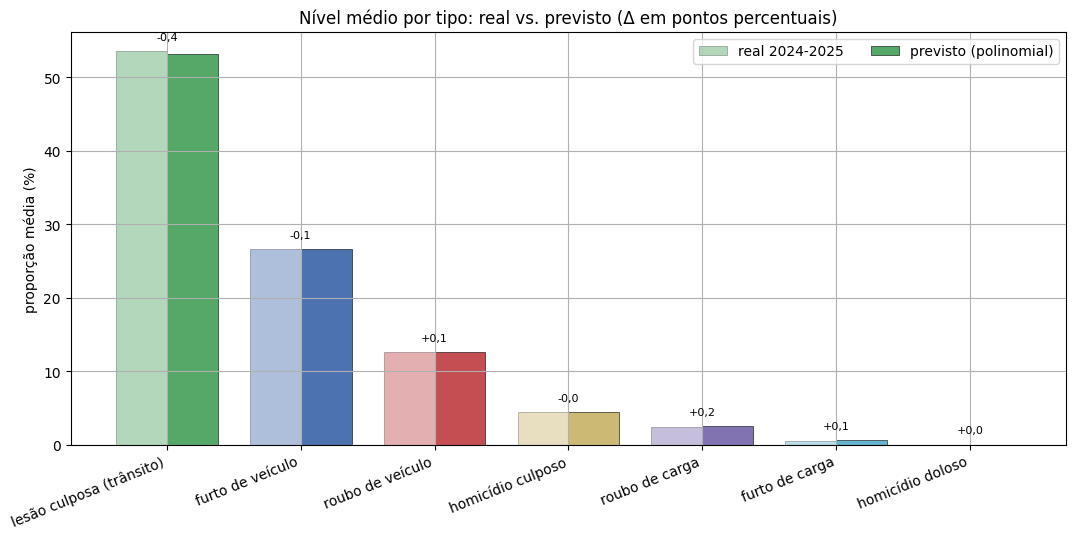

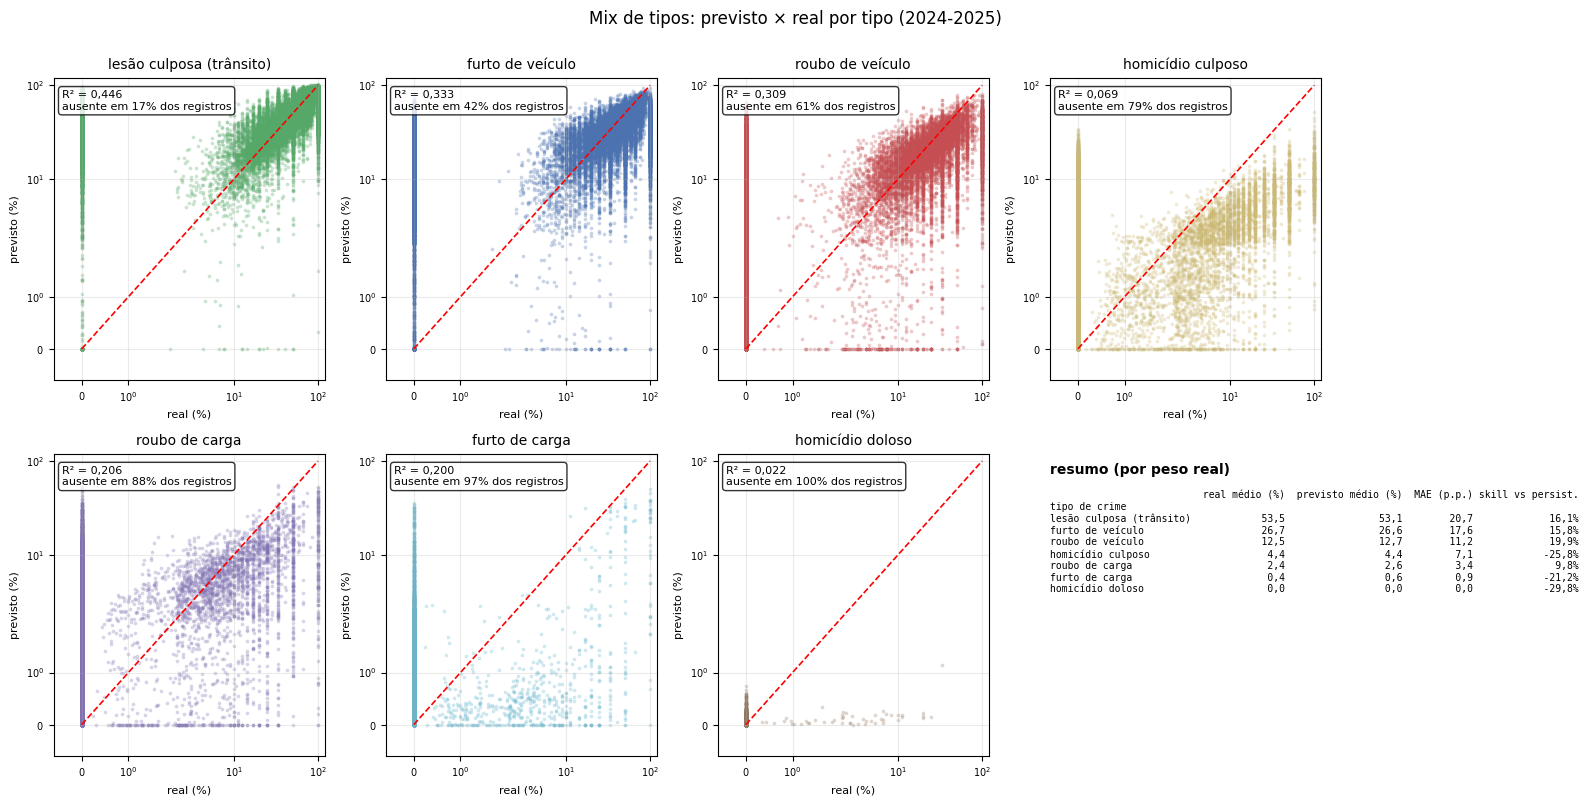

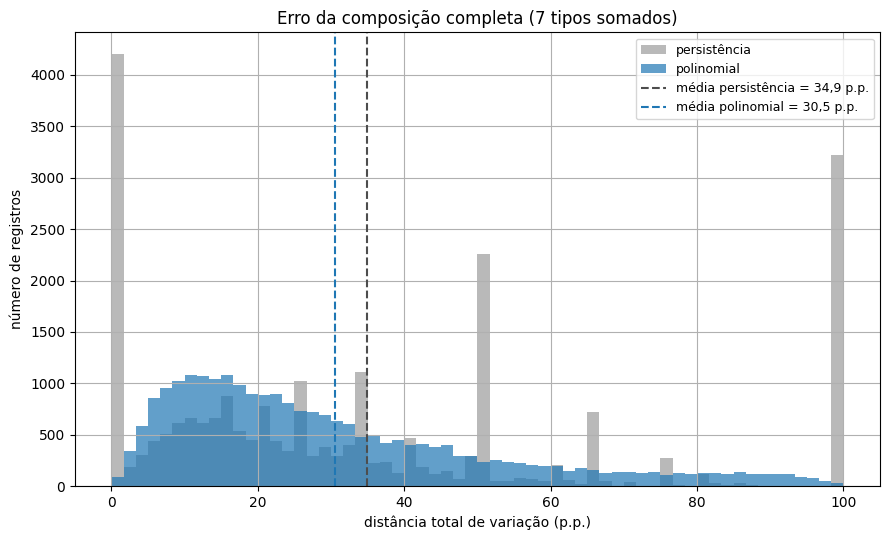

=== DISTÂNCIA TOTAL DE VARIAÇÃO (composição inteira) ===
                           MAE médio (p.p.) Mediana (p.p.) P90 (p.p.)
composição                                                           
Polinomial                            30,49          24,11      65,33
Persistência (mix 2022-23)            34,89          25,00     100,00
Média global                          43,33          46,03      73,33

skill da composição = 12,6%  (veredito: melhor)
0 = mix perfeito; quanto mais à direita, mais trocado está o bolo de tipos


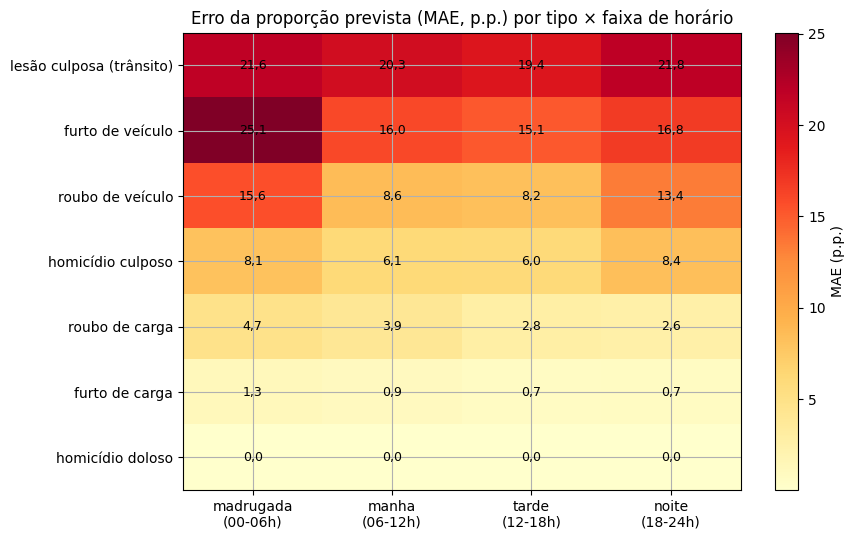

MAE médio do mix = 8,71 p.p. — células acima desse valor são as piores combinações tipo × horário.


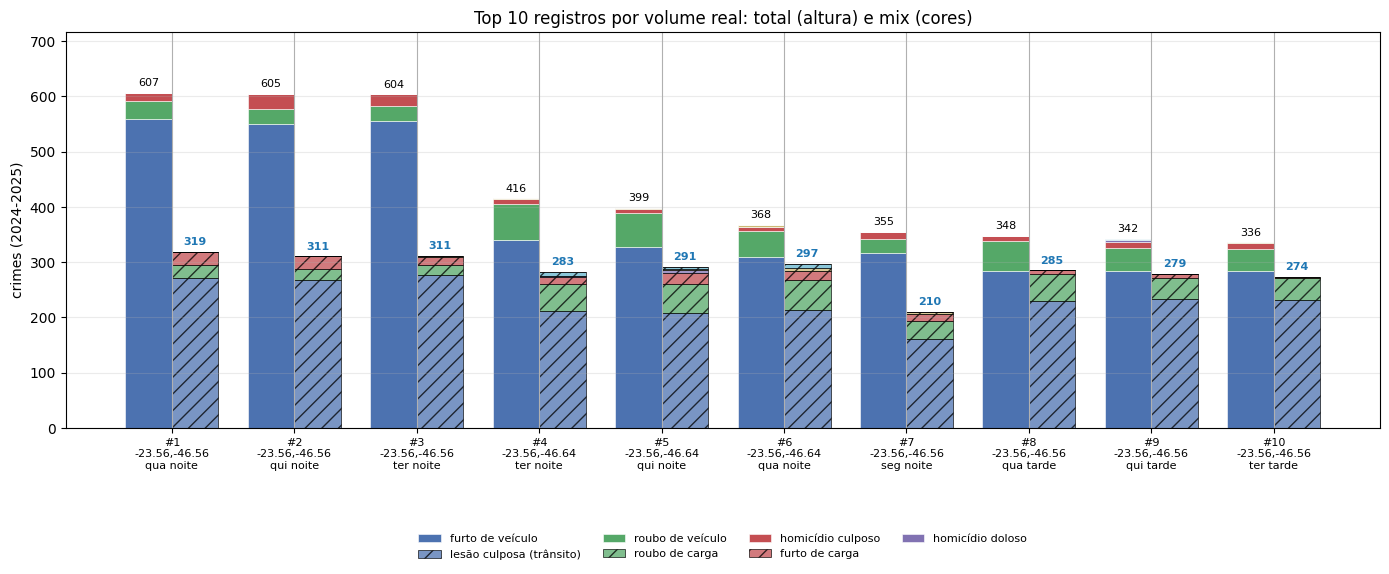

=== TOP 10 REGISTROS POR VOLUME ===
 #        célula     dia          faixa  total real  total previsto  MAE do mix (p.p.)
 1 -23.56/-46.56  quarta noite (18-24h)       607,0           319,4                2,1
 2 -23.56/-46.56  quinta noite (18-24h)       605,0           310,8                1,4
 3 -23.56/-46.56   terca noite (18-24h)       604,0           311,1                0,8
 4 -23.56/-46.64   terca noite (18-24h)       416,0           282,6                1,9
 5 -23.56/-46.64  quinta noite (18-24h)       399,0           291,3                3,2
 6 -23.56/-46.64  quarta noite (18-24h)       368,0           297,4                3,5
 7 -23.56/-46.56 segunda noite (18-24h)       355,0           209,8                3,6
 8 -23.56/-46.56  quarta tarde (12-18h)       348,0           285,2                0,5
 9 -23.56/-46.56  quinta tarde (12-18h)       342,0           278,6                0,6
10 -23.56/-46.56   terca tarde (12-18h)       336,0           273,7                1,0
relatór

In [1]:
CAMINHO_CSV = "SPDadosCriminais_FINAL.csv"

GRADE_GRAUS = 0.04  # lado da célula em graus (~4,4 km lat / 4,1 km lon em -23°)

JANELA_FEAT = (2022, 2023)  # janela que fornece features/histórico
JANELA_ALVO = (2024, 2025)  # janela dos alvos (total + proporções)

EXCLUIR_HORA_INCERTA = False   # True: descarta os 14.774 B.O.s com DESC_PERIODO == 'EM HORA INCERTA'
INCLUIR_MIX_REGISTRO = False   # True: usa o mix (proporções) do próprio registro na janela A
INCLUIR_MIX_CELULA = True      # True: usa o mix da célula inteira na janela A (mais estável)
INCLUIR_AGREGADOS_CELULA = True  # True: usa totais da célula / da célula×faixa / da célula×dia

GRAUS = (1, 2)            # graus do polinômio avaliados na busca (3 = ~6.000 termos, pesado)
TRANSFORMAR_MIX = "fracao"  # "fracao" (igual ao mlp.py) ou "clr" (log-razão centrada)
EPS_CLR = 1e-3             # substituição de zeros antes do log; 1e-3 = 0,1 p.p.
LIMIAR_CAUDA = 0.005       # corta features numéricas em [0,5% ; 99,5%] (winsorização)

N_ITER_BUSCA = 24   # avaliações do RandomizedSearchCV
N_FOLDS = 5
N_JOBS = -1         # processos paralelos; cada um com 1 thread de BLAS
SEED = 42

CARREGAR_MODELO = True   # True: exige poly_melhor.joblib e pula a busca
REUSAR_REGISTROS = True   # True: se registros.csv existir, pula a leitura do CSV de 173 MB
RODAR_IMPORTANCIA = True  # False: pula permutation_importance e o gráfico de importância

ARQ_REGISTROS = "registros.csv"
ARQ_MODELO = "poly_melhor.joblib"
ARQ_BUSCA = "busca_hiperparametros_poly.csv"

# chave do REGISTRO: (célula geográfica, dia da semana, faixa de horário)
CHAVE = ["cel_lat", "cel_lon", "dia_semana", "faixa"]

import re
import time
import unicodedata
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import parallel_config
from scipy.stats import loguniform
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

def slug(texto: str) -> str:
    texto = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return re.sub(r"[^A-Za-z0-9]+", "_", texto).strip("_").upper()


def agregar(dados: pd.DataFrame, tipos: list) -> pd.DataFrame:
    col_tipo = {t: f"prop_{slug(t)}" for t in tipos}
    g = dados.groupby(CHAVE, sort=True)
    out = pd.DataFrame(
        {
            "n_bos": g.size(),
            "n_dias": g["data"].nunique(),
            "n_meses": g["mes"].nunique(),
        }
    )

    mix = (
        g["tipo"]
        .value_counts(normalize=True)
        .unstack(fill_value=0.0)
        .mul(100.0)
        .reindex(columns=tipos, fill_value=0.0)
        .rename(columns=col_tipo)
    )
    out = out.join(mix)

    circ = (
        dados.assign(
            _sh=np.sin(dados["hora_rad"]),
            _ch=np.cos(dados["hora_rad"]),
            _sm=np.sin(dados["mes_rad"]),
            _cm=np.cos(dados["mes_rad"]),
        )
        .groupby(CHAVE, sort=True)[["_sh", "_ch", "_sm", "_cm"]]
        .mean()
    )
    out["hora_sin"] = circ["_sh"]
    out["hora_cos"] = circ["_ch"]
    out["mes_sin"] = circ["_sm"]
    out["mes_cos"] = circ["_cm"]
    out["hora_media"] = (np.arctan2(circ["_sh"], circ["_ch"]) % (2 * np.pi)) / (2 * np.pi) * 24
    out["mes_medio"] = (np.arctan2(circ["_sm"], circ["_cm"]) % (2 * np.pi)) / (2 * np.pi) * 12
    return out.reset_index()


def construir_registros() -> pd.DataFrame:
    """Lê o CSV bruto, aplica a chave (célula, dia da semana, faixa) e agrega as janelas A/B."""
    COLS = [
        "DATA_OCORRENCIA_BO",
        "HORA_OCORRENCIA_BO",
        "DESC_PERIODO",
        "LATITUDE",
        "LONGITUDE",
        "NATUREZA_APURADA",
    ]

    bruto = pd.read_csv(CAMINHO_CSV, usecols=COLS, low_memory=False)
    print(f"linhas brutas: {len(bruto):,}")

    df = bruto.copy()
    df["data"] = pd.to_datetime(df["DATA_OCORRENCIA_BO"], errors="coerce")

    # a coluna de hora aparece em 3 formatos: 'HH:MM:SS', 'YYYY-MM-DD HH:MM:SS' e 'HH:MM:SS.f'
    _extraida = df["HORA_OCORRENCIA_BO"].astype(str).str.extract(r"(\d{1,2}):(\d{2})")
    df["hora"] = pd.to_numeric(_extraida[0], errors="coerce")

    df["lat"] = pd.to_numeric(df["LATITUDE"], errors="coerce")
    df["lon"] = pd.to_numeric(df["LONGITUDE"], errors="coerce")
    df["tipo"] = df["NATUREZA_APURADA"].astype(str).str.strip()

    mascara = (
        df["data"].notna()
        & df["hora"].between(0, 23)
        & df["lat"].between(-25.6, -19.4)
        & df["lon"].between(-53.6, -44.0)
        & df["tipo"].notna()
        & df["tipo"].ne("nan")
    )
    if EXCLUIR_HORA_INCERTA:
        mascara &= df["DESC_PERIODO"].ne("EM HORA INCERTA")

    df = df.loc[mascara].copy()
    print(f"linhas válidas: {len(df):,}  (descartadas: {len(bruto) - len(df):,})")

    NOMES_DIA = ["segunda", "terca", "quarta", "quinta", "sexta", "sabado", "domingo"]
    NOMES_FAIXA = ["madrugada (00-06h)", "manha (06-12h)", "tarde (12-18h)", "noite (18-24h)"]

    df["ano"] = df["data"].dt.year
    df["mes"] = df["data"].dt.month
    df["dia_semana"] = df["data"].dt.day_of_week.map(dict(enumerate(NOMES_DIA)))
    df["faixa"] = (df["hora"] // 6).astype(int).map(dict(enumerate(NOMES_FAIXA)))

    df["cel_lat"] = (df["lat"] / GRADE_GRAUS).round() * GRADE_GRAUS
    df["cel_lon"] = (df["lon"] / GRADE_GRAUS).round() * GRADE_GRAUS
    df[["cel_lat", "cel_lon"]] = df[["cel_lat", "cel_lon"]].round(6)

    df["hora_rad"] = 2 * np.pi * df["hora"] / 24
    df["mes_rad"] = 2 * np.pi * (df["mes"] - 0.5) / 12

    tipos = df["tipo"].value_counts().index.tolist()
    print(f"células: {df.groupby(['cel_lat', 'cel_lon']).ngroups:,}")
    print(f"tipos de crime ({len(tipos)}):")
    for t in tipos:
        print(f"  - {t}")

    reg_A = agregar(df[df["ano"].between(*JANELA_FEAT)], tipos)
    reg_B = agregar(df[df["ano"].between(*JANELA_ALVO)], tipos)
    registros = reg_A.merge(reg_B, on=CHAVE, how="inner", suffixes=("_A", "_B"))

    print(f"registros (chaves) janela A: {len(reg_A):,}")
    print(f"registros (chaves) janela B: {len(reg_B):,}")
    print(f"REGISTROS usados (A ∩ B):    {len(registros):,}")
    return registros

if REUSAR_REGISTROS and Path(ARQ_REGISTROS).exists():
    registros = pd.read_csv(ARQ_REGISTROS)
    print(
        f"REGISTROS lidos do cache {Path(ARQ_REGISTROS).resolve()}\n"
        f"  {registros.shape[0]:,} linhas × {registros.shape[1]} colunas"
    )
else:
    if REUSAR_REGISTROS:
        print(f"cache {ARQ_REGISTROS} não encontrado — reconstruindo do CSV bruto")
    registros = construir_registros()
    registros.to_csv(ARQ_REGISTROS, index=False)
    print(
        f"gravado: {ARQ_REGISTROS}  ({registros.shape[0]:,} linhas × {registros.shape[1]} colunas)"
    )

registros.head()

MIX_A = [c for c in registros.columns if c.startswith("prop_") and c.endswith("_A")]
MIX_B = [c for c in registros.columns if c.startswith("prop_") and c.endswith("_B")]

registros["log_n_bos_A"] = np.log1p(registros["n_bos_A"])

_grupo_cel = registros.groupby(["cel_lat", "cel_lon"])
registros["n_bos_celula_A"] = _grupo_cel["n_bos_A"].transform("sum")
registros["log_n_bos_celula_A"] = np.log1p(registros["n_bos_celula_A"])
registros["share_celula_A"] = registros["n_bos_A"] / registros["n_bos_celula_A"]
registros["n_bos_celula_faixa_A"] = registros.groupby(["cel_lat", "cel_lon", "faixa"])[
    "n_bos_A"
].transform("sum")
registros["n_bos_celula_dia_A"] = registros.groupby(["cel_lat", "cel_lon", "dia_semana"])[
    "n_bos_A"
].transform("sum")

_peso = registros["n_bos_A"]
for _c in MIX_A:
    registros["cel_" + _c] = (
        (registros[_c] * _peso)
        .groupby([registros["cel_lat"], registros["cel_lon"]])
        .transform("sum")
        / registros["n_bos_celula_A"]
    )
CELMIX = ["cel_" + c for c in MIX_A]

print(f"{len(MIX_A)} tipos; exemplos de features de célula:")
print(registros[["n_bos_A", "n_bos_celula_A", "share_celula_A"] + CELMIX[:3]].head(3).to_string(index=False))

BASE_NUM = [
    "cel_lat",
    "cel_lon",
    "hora_sin_A",
    "hora_cos_A",
    "mes_sin_A",
    "mes_cos_A",
    "n_bos_A",
    "log_n_bos_A",
    "n_dias_A",
    "n_meses_A",
]
AGREGADOS_CELULA = [
    "n_bos_celula_A",
    "log_n_bos_celula_A",
    "share_celula_A",
    "n_bos_celula_faixa_A",
    "n_bos_celula_dia_A",
]

CAT = ["dia_semana", "faixa"]
NUM = (
    BASE_NUM
    + (AGREGADOS_CELULA if INCLUIR_AGREGADOS_CELULA else [])
    + (CELMIX if INCLUIR_MIX_CELULA else [])
    + (MIX_A if INCLUIR_MIX_REGISTRO else [])
)

ALVOS = ["n_bos_B"] + MIX_B

X = registros[CAT + NUM].copy()
y = registros[ALVOS].to_numpy(dtype=float)

# --- corte de cauda (winsorização), ver markdown acima -------------------
COLS_CAUDA = [c for c in NUM if c not in ("cel_lat", "cel_lon")]
if LIMIAR_CAUDA > 0:
    for c in COLS_CAUDA:
        lo, hi = X[c].quantile([LIMIAR_CAUDA, 1 - LIMIAR_CAUDA])
        X[c] = X[c].clip(lo, hi)
    print(f"corte de cauda: {len(COLS_CAUDA)} features em "
          f"[{LIMIAR_CAUDA:.1%} ; {1 - LIMIAR_CAUDA:.1%}] (cel_lat/cel_lon preservadas)")

print(f"X: {X.shape[0]:,} registros × {X.shape[1]} features  ({len(CAT)} categóricas + {len(NUM)} numéricas)")
print(f"y: {y.shape[1]} alvos -> {ALVOS[0]} (contagem) + {len(MIX_B)} proporções")

# teto de plausibilidade para o total previsto: protege o `expm1` de extrapolações
# absurdas do polinômio (o log-espaço transforma um erro pequeno em milhões de crimes)
TETO_TOTAL = float(np.ceil(1.05 * y[:, 0].max()))


def _para_clr(props_pct: np.ndarray) -> np.ndarray:
    """proporções em % -> log-razão centrada (trata zeros com EPS_CLR)."""
    q = np.clip(props_pct / 100.0, 0.0, None) + EPS_CLR
    lg = np.log(q)
    return lg - lg.mean(axis=1, keepdims=True)


def _de_clr(z: np.ndarray) -> np.ndarray:
    """log-razão centrada -> proporções em % (positivas, somando 100)."""
    z = z - z.max(axis=1, keepdims=True)
    q = np.exp(z)
    return 100.0 * q / q.sum(axis=1, keepdims=True)


def normalizar_props(p: np.ndarray) -> np.ndarray:
    """corta negativos e re-normaliza cada linha para somar 100%."""
    p = np.clip(p, 0.0, None)
    soma = p.sum(axis=1, keepdims=True)
    return np.divide(p * 100.0, soma, out=np.zeros_like(p), where=soma > 0)


def y_para_treino(y: np.ndarray) -> np.ndarray:
    """total -> log1p | proporções -> CLR ou fração 0..1, conforme TRANSFORMAR_MIX."""
    yt = np.array(y, dtype=float, copy=True)
    yt[:, 0] = np.log1p(yt[:, 0])
    if TRANSFORMAR_MIX == "clr":
        yt[:, 1:] = _para_clr(yt[:, 1:])
    else:
        yt[:, 1:] = yt[:, 1:] / 100.0
    return yt


def y_original(yt: np.ndarray) -> np.ndarray:
    """desfaz a transformação, corta o total em [0, TETO_TOTAL] e renormaliza o mix."""
    y = np.array(yt, dtype=float, copy=True)
    y[:, 0] = np.clip(np.expm1(y[:, 0]), 0.0, TETO_TOTAL)
    if TRANSFORMAR_MIX == "clr":
        y[:, 1:] = _de_clr(y[:, 1:])
    y[:, 1:] = normalizar_props(y[:, 1:])
    return y


y_treino = y_para_treino(y)
print(f"y de treino: total em log1p, mix em '{TRANSFORMAR_MIX}'  |  TETO_TOTAL = {TETO_TOTAL:.0f} crimes")

pre = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
        ("num", StandardScaler(), NUM),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

pipe = Pipeline(
    [
        ("pre", pre),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("ridge", Ridge(alpha=100.0)),
    ]
)
pipe

espaco = {
    "poly__degree": list(GRAUS),
    "poly__interaction_only": [False, True],
    "ridge__alpha": loguniform(1e-2, 1e3),
}

CAMINHO_MODELO = Path(ARQ_MODELO).resolve()

if CARREGAR_MODELO:
    if not CAMINHO_MODELO.exists():
        raise FileNotFoundError(
            "CARREGAR_MODELO = True, mas o modelo treinado não foi encontrado.\n"
            f"  caminho testado: {CAMINHO_MODELO}\n"
            f"  Coloque '{ARQ_MODELO}' nessa pasta (a mesma onde está o CSV) ou mude "
            "ARQ_MODELO para o caminho completo.\n"
            "  Para treinar do zero, defina CARREGAR_MODELO = False."
        )

    print(f"MODELO: carregando de {CAMINHO_MODELO} (busca de hiperparâmetros pulada)")
    modelo = joblib.load(CAMINHO_MODELO)
    busca = None
    resumo_busca = pd.DataFrame()

    esperadas = list(X.columns)
    treinadas = list(getattr(modelo.named_steps["pre"], "feature_names_in_", esperadas))
    if treinadas != esperadas:
        raise ValueError(
            "As features atuais não batem com as do modelo salvo.\n"
            f"  modelo: {treinadas}\n"
            f"  atual : {esperadas}\n"
            "Provável causa: INCLUIR_MIX_REGISTRO / INCLUIR_MIX_CELULA / "
            "INCLUIR_AGREGADOS_CELULA mudou depois do treino (ou as janelas de tempo). "
            "Rode com CARREGAR_MODELO = False para retreinar."
        )

    p = modelo.named_steps["ridge"].get_params()
    print("hiperparâmetros do modelo carregado:")
    for k in ["alpha"]:
        print(f"  ridge__{k}: {p[k]}")
    print(f"  poly__degree: {modelo.named_steps['poly'].degree}")
    print(f"  poly__interaction_only: {modelo.named_steps['poly'].interaction_only}")
    print(f"  termos polinomiais: {len(modelo.named_steps['poly'].get_feature_names_out()):,}")
else:
    print(f"MODELO: treinando do zero (CARREGAR_MODELO = False) -> {CAMINHO_MODELO}")

    busca = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=espaco,
        n_iter=N_ITER_BUSCA,
        scoring="neg_mean_squared_error",
        cv=KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED),
        n_jobs=N_JOBS,
        random_state=SEED,
        refit=True,
        return_train_score=True,
        verbose=1,
    )

    t0 = time.perf_counter()
    with parallel_config(backend="loky", n_jobs=N_JOBS, inner_max_num_threads=1):
        busca.fit(X, y_treino)
    tempo = time.perf_counter() - t0

    print(f"\nconcluído em {tempo/60:.1f} min ({busca.n_splits_} folds × {N_ITER_BUSCA} avaliações)")
    print("melhores hiperparâmetros:")
    for k, v in busca.best_params_.items():
        print(f"  {k}: {v}")
    print(f"melhor MSE (y transformado): {-busca.best_score_:.6f}")

    resumo_busca = pd.DataFrame(busca.cv_results_)
    cols = ["rank_test_score", "mean_test_score", "std_test_score", "mean_fit_time", "params"]
    resumo_busca = resumo_busca.sort_values("rank_test_score")[cols].reset_index(drop=True)
    resumo_busca.to_csv(ARQ_BUSCA, index=False)
    print(f"resultados da busca gravados em {ARQ_BUSCA}")
    print(resumo_busca.head(10).to_string(index=False))

    modelo = busca.best_estimator_

print(f"termos polinomiais do modelo final: {len(modelo.named_steps['poly'].get_feature_names_out()):,}")

pred = y_original(modelo.predict(X))


def metricas_total(real: np.ndarray, prev: np.ndarray) -> dict:
    err = prev - real
    return {
        "RMSE": float(np.sqrt(mean_squared_error(real, prev))),
        "MAE": float(mean_absolute_error(real, prev)),
        "R2": float(r2_score(real, prev)),
        "WAPE_%": float(100 * np.abs(err).sum() / np.abs(real).sum()),
    }


def metricas_props(real: np.ndarray, prev: np.ndarray) -> pd.Series:
    return pd.Series(
        np.abs(prev - real).mean(axis=0),
        index=[c.replace("prop_", "").replace("_B", "") for c in ALVOS[1:]],
        name="MAE_pp",
    )


mae_props_poly = metricas_props(y[:, 1:], pred[:, 1:])

# --- baselines ingênuos -------------------------------------------------
base_media_total = np.full(len(y), y[:, 0].mean())
base_persist_total = registros["n_bos_A"].to_numpy(dtype=float)

mix_hist = registros[MIX_A].to_numpy(dtype=float)
mix_medio = np.tile(y[:, 1:].mean(axis=0), (len(y), 1))


def linha_comparativo(modelo: str, total_prev: np.ndarray, props_prev: np.ndarray) -> dict:
    m = metricas_total(y[:, 0], total_prev)
    return {
        "modelo": modelo,
        "RMSE_total": m["RMSE"],
        "MAE_total": m["MAE"],
        "R2_total": m["R2"],
        "WAPE_total_%": m["WAPE_%"],
        "MAE_mix_pp": float(np.abs(props_prev - y[:, 1:]).mean()),
    }


comparativo = pd.DataFrame(
    [
        linha_comparativo("Polinomial (busca de hiperparâmetros)", pred[:, 0], pred[:, 1:]),
        linha_comparativo("Baseline: constante (média global)", base_media_total, mix_medio),
        linha_comparativo(
            "Baseline: persistência (n_A) / mix histórico", base_persist_total, mix_hist
        ),
    ]
)

print("=== Total de crimes (janela 2024-2025) ===")
print(comparativo.to_string(index=False))
print("\n=== Mix de crimes: MAE por tipo (percentuais pontuais) ===")
print(mae_props_poly.sort_values(ascending=False).to_string())

if RODAR_IMPORTANCIA:
    with parallel_config(backend="loky", n_jobs=N_JOBS, inner_max_num_threads=1):
        imp = permutation_importance(
            modelo,
            X,
            y_treino,
            n_repeats=8,
            random_state=SEED,
            n_jobs=N_JOBS,
            scoring="neg_mean_squared_error",
        )

    ordem = np.argsort(imp.importances_mean)[::-1][:16]
    imp_df = pd.DataFrame(
        {
            "feature": X.columns[ordem],
            "importancia": imp.importances_mean[ordem],
            "std": imp.importances_std[ordem],
        }
    )
else:
    imp_df = pd.DataFrame(columns=["feature", "importancia", "std"])
    print("RODAR_IMPORTANCIA = False — permutation_importance pulada")

if not imp_df.empty:
    print(imp_df.to_string(index=False))

fig, eixos = plt.subplots(2, 2, figsize=(14, 10))

ax = eixos[0, 0]
ax.scatter(y[:, 0], pred[:, 0], s=8, alpha=0.35)
lim = [max(1, y[:, 0].min()), max(y[:, 0].max(), pred[:, 0].max())]
ax.plot(lim, lim, "r--", lw=1)
ax.set_xscale("symlog")
ax.set_yscale("symlog")
ax.set_xlabel("total real (2024-2025)")
ax.set_ylabel("total previsto")
ax.set_title("Total de crimes: previsto vs. real")

ax = eixos[0, 1]
ax.hist(y[:, 0] - pred[:, 0], bins=60)
ax.set_xlabel("resíduo (real - previsto)")
ax.set_ylabel("frequência")
ax.set_title("Distribuição dos resíduos do total")

ax = eixos[1, 0]
mae_props_poly.sort_values().plot.barh(ax=ax)
ax.set_xlabel("MAE (p.p.)")
ax.set_title("Erro médio por tipo de crime")

ax = eixos[1, 1]
if busca is not None and not resumo_busca.empty:
    curva = (
        resumo_busca.assign(grau=resumo_busca["params"].map(lambda p: p["poly__degree"]))
        .groupby("grau")["mean_test_score"]
        .max()
    )
    ax.plot(curva.index, -curva.to_numpy(), "o-")
    ax.set_xticks(list(curva.index))
    ax.set_xlabel("grau do polinômio")
    ax.set_ylabel("melhor MSE de validação (y transformado)")
    ax.set_title("Erro de validação por grau do polinômio")
else:
    coef = np.abs(modelo.named_steps["ridge"].coef_)
    if coef.ndim > 1:  # multi-saída: usa o alvo 0 (total em log1p)
        coef = coef[0]
    nomes = modelo.named_steps["poly"].get_feature_names_out()
    top = np.argsort(coef)[::-1][:12][::-1]
    ax.barh([nomes[i] for i in top], coef[top], color="tab:green")
    ax.set_xlabel("|coeficiente| (alvo total, log1p)")
    ax.set_title("Termos polinomiais de maior peso")
    ax.tick_params(labelsize=7)

plt.tight_layout()
plt.show()

# %%
if RODAR_IMPORTANCIA:
    fig, ax = plt.subplots(figsize=(9, 6))
    imp_ord = imp_df.iloc[::-1]
    ax.barh(imp_ord["feature"], imp_ord["importancia"], xerr=imp_ord["std"])
    ax.set_xlabel("importância (redução média do MSE ao embaralhar)")
    ax.set_title("Importância das features (top 16)")
    plt.tight_layout()
    plt.show()
else:
    print("gráfico de importância pulado (RODAR_IMPORTANCIA = False)")

joblib.dump(modelo, ARQ_MODELO)
print(f"modelo       -> {ARQ_MODELO}")
print(f"registros    -> {ARQ_REGISTROS}")
if busca is not None:
    print(f"hiperparâms. -> {ARQ_BUSCA}")

amostra = registros.assign(
    total_real=y[:, 0], total_previsto=pred[:, 0], erro=pred[:, 0] - y[:, 0]
)[CHAVE + ["n_bos_A", "total_real", "total_previsto", "erro"] + MIX_B[:3]]
amostra.sort_values("n_bos_A", ascending=False).head(10)

# --- configuração e utilitários do relatório (100% locais a esta seção) ----
ARQ_RELATORIO = "relatorio_metricas_poly.csv"
GERAR_MAPA_ESPACIAL = True

TOL_CRIMES = 2.0    # acerto no total: |erro| <= max(2, 10% do total real)
TOL_FRACAO = 0.10   # ^ 10%
TOL_MIX_PP = 5.0    # acerto no mix: |erro| <= 5 pontos percentuais

ORDEM_DIAS = ["segunda", "terca", "quarta", "quinta", "sexta", "sabado", "domingo"]
ORDEM_FAIXAS = ["madrugada (00-06h)", "manha (06-12h)", "tarde (12-18h)", "noite (18-24h)"]


def br(valor, casas: int = 2) -> str:
    """Número no formato pt-BR (1.234,56) ou '—' se não for finito."""
    if valor is None or not np.isfinite(valor):
        return "—"
    return f"{valor:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def r2_seguro(real, prev) -> float:
    real, prev = np.asarray(real, float), np.asarray(prev, float)
    if len(real) < 2 or np.var(real) == 0:
        return float("nan")
    return float(r2_score(real, prev))


def como_texto(df: pd.DataFrame, inteiros=("n",), tres=("R²",)) -> pd.DataFrame:
    """Converte colunas numéricas p/ string com formatação pt-BR
    (inteiro sem casas, 'R²' — linha ou coluna — com 3 casas, demais com 2)."""
    out = df.copy()
    for col in out.columns:
        if not pd.api.types.is_numeric_dtype(out[col]):
            continue
        if col in inteiros:
            out[col] = [
                "—" if not np.isfinite(v) else f"{int(v):,}".replace(",", ".") for v in out[col]
            ]
        else:
            out[col] = [
                br(v, 3) if (idx in tres or col in tres) else br(v, 2)
                for idx, v in zip(out.index, out[col])
            ]
    return out


def metricas_total_detalhado(real, prev) -> dict:
    real, prev = np.asarray(real, float), np.asarray(prev, float)
    err = prev - real
    tol = np.maximum(TOL_CRIMES, TOL_FRACAO * real)
    return {
        "MAE (crimes)": float(np.mean(np.abs(err))),
        "Mediana do |erro| (crimes)": float(np.median(np.abs(err))),
        "RMSE (crimes)": float(np.sqrt(np.mean(err**2))),
        "WAPE (%)": float(100 * np.abs(err).sum() / np.abs(real).sum()),
        "Acerto ±tolerância (%)": float(100 * np.mean(np.abs(err) <= tol)),
        "R²": r2_seguro(real, prev),
        "Sesgo médio (crimes)": float(np.mean(err)),
    }


def metricas_mix_detalhado(real, prev) -> dict:
    real, prev = np.asarray(real, float), np.asarray(prev, float)
    d = np.abs(prev - real)
    return {
        "MAE do mix (p.p.)": float(d.mean()),
        "Acerto do mix ±5 p.p. (%)": float(100 * np.mean(d <= TOL_MIX_PP)),
        "Sesgo do mix (p.p.)": float((prev - real).mean()),
    }


MENOR_MELHOR = {
    "MAE (crimes)": True,
    "Mediana do |erro| (crimes)": True,
    "RMSE (crimes)": True,
    "WAPE (%)": True,
    "Acerto ±tolerância (%)": False,
    "R²": False,
    "Sesgo médio (crimes)": None,
    "MAE do mix (p.p.)": True,
    "Acerto do mix ±5 p.p. (%)": False,
    "Sesgo do mix (p.p.)": None,
}


def _skill(val, ref, menor_melhor, nome) -> str:
    if not np.isfinite(val) or not np.isfinite(ref) or ref == 0:
        return "—"
    if menor_melhor:
        return f"{br(100 * (1 - val / ref), 1)}%"
    delta = val - ref
    if "%" in nome:  # métricas em % -> diferença em pontos percentuais
        return f"{'+' if delta >= 0 else ''}{br(delta, 1)} p.p."
    return f"{'+' if delta >= 0 else ''}{br(delta, 3)}"


def _veredito(val, ref, menor_melhor) -> str:
    if not np.isfinite(val) or not np.isfinite(ref):
        return "—"
    if menor_melhor:
        if ref == 0:
            return "igual"
        if val < ref * 0.99:
            return "melhor"
        if val > ref * 1.01:
            return "pior"
        return "igual"
    if val > ref + 0.005:
        return "melhor"
    if val < ref - 0.005:
        return "pior"
    return "igual"


def _rotulo_vies(val) -> str:
    if not np.isfinite(val):
        return "—"
    if abs(val) < 0.5:
        return "quase sem viés"
    return "superestima" if val > 0 else "subestima"


total_real = y[:, 0]
resumo = {
    "Polinomial": {
        **metricas_total_detalhado(total_real, pred[:, 0]),
        **metricas_mix_detalhado(y[:, 1:], pred[:, 1:]),
    },
    "Persistência": {
        **metricas_total_detalhado(total_real, base_persist_total),
        **metricas_mix_detalhado(y[:, 1:], mix_hist),
    },
    "Média global": {
        **metricas_total_detalhado(total_real, base_media_total),
        **metricas_mix_detalhado(y[:, 1:], mix_medio),
    },
}

ORDENACAO = list(MENOR_MELHOR)

linhas = []
for nome in ORDENACAO:
    poly_v = resumo["Polinomial"][nome]
    per_v = resumo["Persistência"][nome]
    med_v = resumo["Média global"][nome]
    menor = MENOR_MELHOR[nome]
    if menor is None:
        skill, ver = "—", _rotulo_vies(poly_v)
    else:
        skill, ver = _skill(poly_v, per_v, menor, nome), _veredito(poly_v, per_v, menor)
    linhas.append(
        {
            "métrica": nome,
            "Polinomial": poly_v,
            "Persistência": per_v,
            "Média global": med_v,
            "skill vs persist.": skill,
            "veredito": ver,
        }
    )

rel_resumo = pd.DataFrame(linhas).set_index("métrica")

skill_total = 100 * (
    1 - resumo["Polinomial"]["MAE (crimes)"] / resumo["Persistência"]["MAE (crimes)"]
)
skill_mix = 100 * (
    1
    - resumo["Polinomial"]["MAE do mix (p.p.)"]
    / resumo["Persistência"]["MAE do mix (p.p.)"]
)

print("=" * 92)
print(f"RESUMO DA PREVISÃO — janela de teste 2024-2025 ({len(registros):,} registros)")
print("=" * 92)
print(
    f"  total de crimes : o modelo polinomial erra {br(skill_total, 1)}% a MENOS que a persistência"
    f"\n                     (MAE {br(resumo['Polinomial']['MAE (crimes)'])} vs "
    f"{br(resumo['Persistência']['MAE (crimes)'])} crimes por registro)"
)
print(
    f"  mix de tipos    : o modelo polinomial erra {br(skill_mix, 1)}% a MENOS"
    f"\n                     (MAE {br(resumo['Polinomial']['MAE do mix (p.p.)'])} vs "
    f"{br(resumo['Persistência']['MAE do mix (p.p.)'])} pontos percentuais)"
)
print(
    f"  indicadores     : R² = {br(resumo['Polinomial']['R²'], 3)} | "
    f"WAPE = {br(resumo['Polinomial']['WAPE (%)'], 1)}% | "
    f"acerto ±tolerância = {br(resumo['Polinomial']['Acerto ±tolerância (%)'], 1)}% | "
    f"sesgo = {br(resumo['Polinomial']['Sesgo médio (crimes)'])} crimes"
)
print("=" * 92)
print(
    "\nSkill > 0 = melhor do que repetir 2022-23 | veredito = modelo vs persistência\n"
    "|sesgo| < 0,5 é tratado como 'quase sem viés'\n"
    "Atenção: as métricas de 'Acerto ±tolerância' podem discordar do MAE — a\n"
    "persistência acerta mais pontos isolados mesmo tendo erro médio maior.\n"
)
print(como_texto(rel_resumo).to_string())

erro_df = registros[CHAVE].copy()
erro_df["real"] = total_real
erro_df["prev"] = pred[:, 0]
erro_df["err"] = erro_df["prev"] - erro_df["real"]
erro_df["abs_err"] = erro_df["err"].abs()
erro_df["ok"] = erro_df["abs_err"] <= np.maximum(TOL_CRIMES, TOL_FRACAO * erro_df["real"])


def resumo_grupo(g: pd.DataFrame) -> pd.Series:
    real = g["real"].to_numpy()
    err = g["err"].to_numpy()
    return pd.Series(
        {
            "n": len(g),
            "MAE (crimes)": float(np.abs(err).mean()),
            "WAPE (%)": float(100 * np.abs(err).sum() / real.sum()) if real.sum() else np.nan,
            "R²": r2_seguro(real, g["prev"].to_numpy()),
            "Acerto ±tol (%)": float(100 * g["ok"].mean()),
            "Sesgo (crimes)": float(err.mean()),
        }
    )


COLS_GRUPO = ["real", "prev", "err", "abs_err", "ok"]
por_faixa = (
    erro_df.groupby("faixa")[COLS_GRUPO]
    .apply(resumo_grupo)
    .reindex(ORDEM_FAIXAS)
    .rename_axis("faixa de horário")
)
por_dia = (
    erro_df.groupby("dia_semana")[COLS_GRUPO]
    .apply(resumo_grupo)
    .reindex(ORDEM_DIAS)
    .rename_axis("dia da semana")
)

por_faixa["n"] = por_faixa["n"].astype(int)
por_dia["n"] = por_dia["n"].astype(int)

print("=== MAE / WAPE / R² POR FAIXA DE HORÁRIO ===")
print(como_texto(por_faixa).to_string())
print("\n=== MAE / WAPE / R² POR DIA DA SEMANA ===")
print(como_texto(por_dia).to_string())

# %%
matriz = (
    erro_df.pivot_table(
        index="dia_semana", columns="faixa", values="abs_err", aggfunc="mean"
    )
    .reindex(index=ORDEM_DIAS, columns=ORDEM_FAIXAS)
)

fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(matriz.to_numpy(dtype=float), cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(ORDEM_FAIXAS)), [f.replace(" (", "\n(") for f in ORDEM_FAIXAS])
ax.set_yticks(range(len(ORDEM_DIAS)), ORDEM_DIAS)
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        v = matriz.iloc[i, j]
        if np.isfinite(v):
            ax.text(j, i, br(v, 1), ha="center", va="center", fontsize=9)
ax.set_title("Erro absoluto médio (MAE, crimes) por dia da semana × faixa de horário")
fig.colorbar(im, ax=ax, label="MAE (crimes)")
plt.tight_layout()
plt.show()

print("quanto mais escuro, pior; compare com o MAE global de "
      f"{br(resumo['Polinomial']['MAE (crimes)'])} crimes")

cal = pd.DataFrame({"prev": pred[:, 0], "real": total_real})
cal["faixa_prev"] = pd.qcut(cal["prev"], 10, duplicates="drop")
calibracao = (
    cal.groupby("faixa_prev", observed=True)
    .agg(prev_medio=("prev", "mean"), real_medio=("real", "mean"), n=("real", "size"))
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(calibracao["prev_medio"], calibracao["real_medio"], s=70, color="tab:blue",
           edgecolor="k", zorder=3, label="deciles do previsto")
limite = [
    min(calibracao["prev_medio"].min(), calibracao["real_medio"].min()),
    max(calibracao["prev_medio"].max(), calibracao["real_medio"].max()),
]
ax.plot(limite, limite, "r--", lw=1.5, label="perfeição (y = x)")
ax.set_xlabel("total médio PREVISTO (deciles)")
ax.set_ylabel("total médio REAL")
ax.set_title("Calibração: previsto vs. real (acima da linha = subestima)")
ax.legend()
plt.tight_layout()
plt.show()

# %%
bins_porte = pd.cut(
    total_real,
    bins=[0, 1, 4, 9, 24, 99, np.inf],
    labels=["1", "2-4", "5-9", "10-24", "25-99", "100+"],
)
df_porte = pd.DataFrame({"bin": bins_porte, "err": pred[:, 0] - total_real, "real": total_real})


def resumo_porte(g: pd.DataFrame) -> pd.Series:
    err, real = g["err"].to_numpy(), g["real"].to_numpy()
    tol = np.maximum(TOL_CRIMES, TOL_FRACAO * real)
    return pd.Series(
        {
            "n": len(g),
            "MAE (crimes)": float(np.abs(err).mean()),
            "WAPE (%)": float(100 * np.abs(err).sum() / real.sum()) if real.sum() else np.nan,
            "Acerto ±tol (%)": float(100 * np.mean(np.abs(err) <= tol)),
        }
    )


por_porte = df_porte.groupby("bin", observed=True)[["err", "real"]].apply(resumo_porte)

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(
    por_porte.index.astype(str), por_porte["MAE (crimes)"], color="tab:orange", alpha=0.85
)
ax.set_xlabel("porte do registro (total real de crimes em 2024-2025)")
ax.set_ylabel("MAE (crimes)")
ax.set_title("Erro por porte do registro")
for rect, n in zip(barras, por_porte["n"]):
    ax.text(
        rect.get_x() + rect.get_width() / 2,
        rect.get_height(),
        f"n={int(n):,}",
        ha="center",
        va="bottom",
        fontsize=8,
    )
plt.tight_layout()
plt.show()

por_porte["n"] = por_porte["n"].astype(int)

print("=== ERRO POR PORTE DO REGISTRO ===")
print(como_texto(por_porte).to_string())

# %%
if GERAR_MAPA_ESPACIAL:
    cel = erro_df.groupby(["cel_lat", "cel_lon"]).agg(
        mae=("abs_err", "mean"), n=("real", "size")
    ).reset_index()

    fig, ax = plt.subplots(figsize=(9, 7))
    sc = ax.scatter(
        cel["cel_lon"], cel["cel_lat"],
        c=cel["mae"], s=np.log1p(cel["n"]) * 14, cmap="magma", alpha=0.85, linewidths=0
    )
    ax.set_xlabel("longitude (célula ~4 km)")
    ax.set_ylabel("latitude (célula ~4 km)")
    ax.set_title("Erro absoluto médio por célula geográfica (2024-2025)")
    fig.colorbar(sc, ax=ax, label="MAE (crimes)")
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
    print(f"{len(cel):,} células com registros em ambas as janelas "
          "(bolha maior = mais registros na célula)")
else:
    print("mapa espacial pulado (GERAR_MAPA_ESPACIAL = False)")

# %%
rel_faixa = por_faixa.reset_index().assign(secao="por_faixa")
rel_dia = por_dia.reset_index().assign(secao="por_dia")
rel_resumo_csv = rel_resumo.reset_index().assign(secao="resumo")
rel_csv = pd.concat([rel_resumo_csv, rel_faixa, rel_dia], ignore_index=True, sort=False)
rel_csv.to_csv(ARQ_RELATORIO, index=False)
print(f"relatório tabular gravado em {ARQ_RELATORIO} "
      f"({len(rel_csv)} linhas: resumo + por_faixa + por_dia)")

ROTULOS_TIPO = {
    "LESAO_CORPORAL_CULPOSA_POR_ACIDENTE_DE_TRANSITO": "lesão culposa (trânsito)",
    "FURTO_DE_VEICULO": "furto de veículo",
    "ROUBO_DE_VEICULO": "roubo de veículo",
    "HOMICIDIO_CULPOSO_POR_ACIDENTE_DE_TRANSITO": "homicídio culposo",
    "ROUBO_DE_CARGA": "roubo de carga",
    "FURTO_DE_CARGA": "furto de carga",
    "HOMICIDIO_DOLOSO_POR_ACIDENTE_DE_TRANSITO": "homicídio doloso",
}
CORES_TIPO = [
    "#4c72b0",
    "#55a868",
    "#c44e52",
    "#8172b2",
    "#ccb974",
    "#64b5cd",
    "#937860",
]

SLUGS_TIPO = [c.replace("prop_", "").replace("_B", "") for c in MIX_B]
ROTULO_TIPO = {s: ROTULOS_TIPO.get(s, s.lower().replace("_", " ")) for s in SLUGS_TIPO}
NOMES_TIPO = [ROTULO_TIPO[s] for s in SLUGS_TIPO]

real_mix = y[:, 1:].astype(float)  # (n x 7) proporções reais em %
prev_mix = pred[:, 1:].astype(float)  # previstas pelo modelo (somam 100%)
hist_mix = mix_hist  # mix de 2022-23 (persistência)

print(f"{len(NOMES_TIPO)} tipos, na ordem dos alvos (MIX_B):")
for j, s in enumerate(SLUGS_TIPO):
    print(f"  {NOMES_TIPO[j]:<28} -> {s}")

def metricas_tipo(j: int) -> dict:
    r_, p_, h = real_mix[:, j], prev_mix[:, j], hist_mix[:, j]
    err = p_ - r_
    mae = float(np.abs(err).mean())
    mae_hist = float(np.abs(h - r_).mean())
    return {
        "% registros sem o tipo": float(100 * (r_ == 0).mean()),
        "real médio (%)": float(r_.mean()),
        "previsto médio (%)": float(p_.mean()),
        "Δ nível (p.p.)": float(p_.mean() - r_.mean()),
        "MAE (p.p.)": mae,
        "Mediana do |erro| (p.p.)": float(np.median(np.abs(err))),
        "RMSE (p.p.)": float(np.sqrt(np.mean(err**2))),
        "Acerto ±5 p.p. (%)": float(100 * np.mean(np.abs(err) <= TOL_MIX_PP)),
        "R²": r2_seguro(r_, p_),
        "Sesgo (p.p.)": float(err.mean()),
        "skill vs persist.": _skill(mae, mae_hist, True, "MAE (p.p.)"),
        "veredito": _veredito(mae, mae_hist, True),
    }


por_tipo = pd.DataFrame.from_dict(
    {NOMES_TIPO[j]: metricas_tipo(j) for j in range(len(NOMES_TIPO))},
    orient="index",
).rename_axis("tipo de crime")
por_tipo = por_tipo.loc[por_tipo["real médio (%)"].sort_values(ascending=False).index]

print("=== MIX POR TIPO — polinomial vs. persistência (janela 2024-2025) ===")
print(como_texto(por_tipo).to_string())
print(
    f"\ntipos com erro menor que a persistência: "
    f"{int((por_tipo['veredito'] == 'melhor').sum())}/{len(por_tipo)}"
    f"   |   piores: {int((por_tipo['veredito'] == 'pior').sum())}"
)
print("Δ nível > 0 = o modelo cria o tipo demais | Δ nível < 0 = abandona o tipo")

ordem_tipo = por_tipo.index.tolist()
idx_ordem = [NOMES_TIPO.index(n) for n in ordem_tipo]
cores_ordem = [CORES_TIPO[j] for j in idx_ordem]
real_b = por_tipo["real médio (%)"].to_numpy(dtype=float)
prev_b = por_tipo["previsto médio (%)"].to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(ordem_tipo))
w = 0.38
ax.bar(
    x - w / 2, real_b, w, color=cores_ordem, alpha=0.45,
    edgecolor="k", linewidth=0.4, label="real 2024-2025",
)
ax.bar(
    x + w / 2, prev_b, w, color=cores_ordem, alpha=1.0,
    edgecolor="k", linewidth=0.4, label="previsto (polinomial)",
)
for i, d in enumerate(por_tipo["Δ nível (p.p.)"]):
    ax.text(
        x[i], max(real_b[i], prev_b[i]) + 1.5,
        f"{'+' if d >= 0 else ''}{br(d, 1)}",
        ha="center", fontsize=8,
    )
ax.set_xticks(x, ordem_tipo, rotation=22, ha="right")
ax.set_ylabel("proporção média (%)")
ax.set_title("Nível médio por tipo: real vs. previsto (Δ em pontos percentuais)")
ax.legend(ncols=2)
plt.tight_layout()
plt.show()

fig, eixos = plt.subplots(2, 4, figsize=(16, 8))
eixos = eixos.ravel()
TETO = 100.0  # proporções ficam em [0, 100] %

for k, ax in enumerate(eixos[: len(NOMES_TIPO)]):
    j = idx_ordem[k]  # mesma ordem da tabela 13.1 (do mais frequente ao mais raro)
    r_, p_ = real_mix[:, j], prev_mix[:, j]
    ax.scatter(r_, p_, s=7, alpha=0.3, color=CORES_TIPO[j], linewidths=0)
    ax.plot([0, TETO], [0, TETO], "r--", lw=1.2)
    ax.set_xscale("symlog")
    ax.set_yscale("symlog")
    ax.set_xlim(-0.6, TETO * 1.2)
    ax.set_ylim(-0.6, TETO * 1.2)
    ax.set_title(NOMES_TIPO[j], fontsize=10)
    ax.set_xlabel("real (%)", fontsize=8)
    ax.set_ylabel("previsto (%)", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.grid(alpha=0.25)
    ax.text(
        0.03, 0.96,
        f"R² = {br(r2_seguro(r_, p_), 3)}\n"
        f"ausente em {br(100 * (r_ == 0).mean(), 0)}% dos registros",
        transform=ax.transAxes, va="top", ha="left", fontsize=8,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8),
    )

ax = eixos[len(NOMES_TIPO)]
ax.axis("off")
ax.text(
    0.0, 0.97,
    "resumo (por peso real)",
    transform=ax.transAxes, fontsize=10, fontweight="bold", va="top",
)
ax.text(
    0.0, 0.88,
    por_tipo[["real médio (%)", "previsto médio (%)", "MAE (p.p.)", "skill vs persist."]].to_string(
        float_format=lambda v: br(v, 1)
    ),
    transform=ax.transAxes, fontsize=7, va="top", family="monospace",
)

fig.suptitle("Mix de tipos: previsto × real por tipo (2024-2025)", y=1.0)
plt.tight_layout()
plt.show()

tvd = {
    "Polinomial": 0.5 * np.abs(prev_mix - real_mix).sum(axis=1),
    "Persistência (mix 2022-23)": 0.5 * np.abs(hist_mix - real_mix).sum(axis=1),
    "Média global": 0.5 * np.abs(mix_medio - real_mix).sum(axis=1),
}

tvd_tabela = pd.DataFrame(
    [
        {
            "composição": nome,
            "MAE médio (p.p.)": float(v.mean()),
            "Mediana (p.p.)": float(np.median(v)),
            "P90 (p.p.)": float(np.percentile(v, 90)),
        }
        for nome, v in tvd.items()
    ]
).set_index("composição")

ref_tvd = tvd["Persistência (mix 2022-23)"].mean()
skill_tvd = 100 * (1 - tvd["Polinomial"].mean() / ref_tvd)
ver_tvd = _veredito(tvd["Polinomial"].mean(), ref_tvd, True)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.hist(tvd["Persistência (mix 2022-23)"], bins=60, alpha=0.55, color="0.5", label="persistência")
ax.hist(tvd["Polinomial"], bins=60, alpha=0.7, color="tab:blue", label="polinomial")
ax.axvline(
    ref_tvd, color="0.3", ls="--", lw=1.5,
    label=f"média persistência = {br(ref_tvd, 1)} p.p.",
)
ax.axvline(
    tvd["Polinomial"].mean(), color="tab:blue", ls="--", lw=1.5,
    label=f"média polinomial = {br(tvd['Polinomial'].mean(), 1)} p.p.",
)
ax.set_xlabel("distância total de variação (p.p.)")
ax.set_ylabel("número de registros")
ax.set_title("Erro da composição completa (7 tipos somados)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print("=== DISTÂNCIA TOTAL DE VARIAÇÃO (composição inteira) ===")
print(como_texto(tvd_tabela).to_string())
print(
    f"\nskill da composição = {br(skill_tvd, 1)}%  (veredito: {ver_tvd})\n"
    "0 = mix perfeito; quanto mais à direita, mais trocado está o bolo de tipos"
)

df_err_mix = pd.DataFrame(np.abs(prev_mix - real_mix), columns=NOMES_TIPO)
df_err_mix["faixa"] = registros["faixa"].to_numpy()

mat_mix = (
    df_err_mix.groupby("faixa")[NOMES_TIPO]
    .mean()
    .T.reindex(index=por_tipo.index, columns=ORDEM_FAIXAS)
)

fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(mat_mix.to_numpy(dtype=float), cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(ORDEM_FAIXAS)), [f.replace(" (", "\n(") for f in ORDEM_FAIXAS])
ax.set_yticks(range(len(mat_mix.index)), mat_mix.index)
for i in range(mat_mix.shape[0]):
    for j in range(mat_mix.shape[1]):
        v = mat_mix.iloc[i, j]
        if np.isfinite(v):
            ax.text(j, i, br(v, 1), ha="center", va="center", fontsize=9)
ax.set_title("Erro da proporção prevista (MAE, p.p.) por tipo × faixa de horário")
fig.colorbar(im, ax=ax, label="MAE (p.p.)")
plt.tight_layout()
plt.show()

print(
    f"MAE médio do mix = {br(resumo['Polinomial']['MAE do mix (p.p.)'])} p.p. — "
    "células acima desse valor são as piores combinações tipo × horário."
)

n_top = 10
idx_top = np.argsort(total_real)[::-1][:n_top]

real_top = real_mix[idx_top] / 100 * total_real[idx_top][:, None]
prev_top = prev_mix[idx_top] / 100 * pred[idx_top, 0][:, None]


def rotulo_registro(i: int) -> str:
    rec = registros.iloc[i]
    return (
        f"{rec['cel_lat']:.2f},{rec['cel_lon']:.2f}\n"
        f"{str(rec['dia_semana'])[:3]} {str(rec['faixa']).split(' ')[0]}"
    )


fig, ax = plt.subplots(figsize=(14, 6))
larg = 0.38
x = np.arange(n_top)
base_r = np.zeros(n_top)
base_p = np.zeros(n_top)
for j in range(len(NOMES_TIPO)):
    ax.bar(
        x - larg / 2, real_top[:, j], larg, bottom=base_r,
        color=CORES_TIPO[j], edgecolor="w", linewidth=0.4,
    )
    ax.bar(
        x + larg / 2, prev_top[:, j], larg, bottom=base_p,
        color=CORES_TIPO[j], alpha=0.75, edgecolor="k", linewidth=0.6, hatch="//",
    )
    base_r += real_top[:, j]
    base_p += prev_top[:, j]

topo = max(base_r.max(), base_p.max())
for i in range(n_top):
    ax.text(x[i] - larg / 2, base_r[i] + topo * 0.02, br(total_real[idx_top[i]], 0),
            ha="center", fontsize=8)
    ax.text(x[i] + larg / 2, base_p[i] + topo * 0.02, br(pred[idx_top[i], 0], 0),
            ha="center", fontsize=8, color="tab:blue", fontweight="bold")

ax.set_xticks(x, [f"#{k + 1}\n{rotulo_registro(i)}" for k, i in enumerate(idx_top)], fontsize=8)
ax.set_ylim(0, topo * 1.18)
ax.set_ylabel("crimes (2024-2025)")
ax.set_title("Top 10 registros por volume real: total (altura) e mix (cores)")
ax.legend(
    NOMES_TIPO, ncols=4, fontsize=8, loc="upper center",
    bbox_to_anchor=(0.5, -0.24), frameon=False,
)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

top_df = pd.DataFrame(
    {
        "#": range(1, n_top + 1),
        "célula": [f"{registros.iloc[i]['cel_lat']:.2f}/{registros.iloc[i]['cel_lon']:.2f}" for i in idx_top],
        "dia": [registros.iloc[i]["dia_semana"] for i in idx_top],
        "faixa": [registros.iloc[i]["faixa"] for i in idx_top],
        "total real": total_real[idx_top],
        "total previsto": pred[idx_top, 0],
        "MAE do mix (p.p.)": np.abs(prev_mix[idx_top] - real_mix[idx_top]).mean(axis=1),
    }
)
print("=== TOP 10 REGISTROS POR VOLUME ===")
print(top_df.to_string(index=False, float_format=lambda v: br(v, 1)))

rel_tipo = por_tipo.reset_index().assign(secao="por_tipo")
rel_comp = tvd_tabela.reset_index().assign(secao="composicao")
rel_csv = pd.concat([rel_csv, rel_tipo, rel_comp], ignore_index=True, sort=False)
rel_csv.to_csv(ARQ_RELATORIO, index=False)
print(
    f"relatório regravado em {ARQ_RELATORIO} — {len(rel_csv)} linhas, "
    f"{rel_csv['secao'].nunique()} seções: "
    f"{', '.join(str(s) for s in rel_csv['secao'].dropna().unique())}"
)